# Lab 03 – Developing a Tiny Transformer Language Model

Module: PUSL 3205 – Large Language Models and Generative AI

## Objective

To develop a small Transformer-based language model
from scratch using the TinyStories dataset.

The model implements character-level tokenization,
masked multi-head self-attention, positional embeddings,
feed-forward networks, next-token prediction,
model evaluation and story generation.

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import math
import time
import random

from pathlib import Path
from collections import Counter

from datasets import load_dataset
from IPython.display import display

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Locate the Lab 03 directory

current_dir = Path.cwd()

possible_paths = [
    current_dir,
    current_dir.parent,
    current_dir / "Lab-03-Tiny-Transformer"
]

project_dir = next(
    (
        p for p in possible_paths
        if (p / "notebooks" / "lab03_tiny_transformer.ipynb").exists()
    ),
    None
)

if project_dir is None:
    raise FileNotFoundError("Lab 03 folder not found")

models_dir = project_dir / "models"
results_dir = project_dir / "results"
screenshots_dir = project_dir / "screenshots"

models_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)
screenshots_dir.mkdir(exist_ok=True)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Automatically select GPU or CPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if device.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
else:
    torch.set_num_threads(min(4, torch.get_num_threads()))

print("Project directory:", project_dir)
print("Using device:", device)
print("PyTorch version:", torch.__version__)

Project directory: c:\Users\DELL\Downloads\LLM-Practical-Portfolio\Lab-03-Tiny-Transformer
Using device: cpu
PyTorch version: 2.15.0+cpu


In [6]:
# Load the dataset using streaming mode

train_dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train",
    streaming=True
)

validation_dataset = load_dataset(
    "roneneldan/TinyStories",
    split="validation",
    streaming=True
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
TRAIN_STORIES = 500
VALIDATION_STORIES = 100

train_stories = [
    item["text"]
    for item in train_dataset.take(TRAIN_STORIES)
]

validation_stories = [
    item["text"]
    for item in validation_dataset.take(VALIDATION_STORIES)
]

print("Training stories:", len(train_stories))
print("Validation stories:", len(validation_stories))
print("Total stories:",
      len(train_stories) + len(validation_stories))

Training stories: 500
Validation stories: 100
Total stories: 600


In [9]:
for i in range(3):

    print("=" * 60)

    print(f"Story {i + 1}")

    print("=" * 60)

    print(train_stories[i])

    print()

Story 1
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.

Story 2
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had many leaves tha

In [10]:
df = pd.DataFrame({
    "story": train_stories
})

df["character_count"] = df["story"].apply(len)

df["word_count"] = df["story"].apply(
    lambda text: len(text.split())
)

df.head()

,story,character_count,word_count
0,"One day, a little girl named Lily found a need...",701,134
1,"Once upon a time, there was a little car named...",705,142
2,"One day, a little fish named Fin was swimming ...",822,168
3,"Once upon a time, in a land full of trees, the...",845,163
4,"Once upon a time, there was a little girl name...",638,129


In [11]:
print("Dataset information:")

df.info()

print("\nMissing values:")

print(df.isnull().sum())

print("\nStory length statistics:")

display(
    df[["character_count", "word_count"]].describe()
)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   story            500 non-null    str  
 1   character_count  500 non-null    int64
 2   word_count       500 non-null    int64
dtypes: int64(2), str(1)
memory usage: 406.4 KB

Missing values:
story              0
character_count    0
word_count         0
dtype: int64

Story length statistics:


,character_count,word_count
count,500.000000,500.000000
mean,804.868000,154.604000
std,165.871533,31.144488
min,320.000000,66.000000
25%,685.000000,133.000000
50%,796.500000,152.500000
75%,919.500000,176.000000
max,1225.000000,242.000000


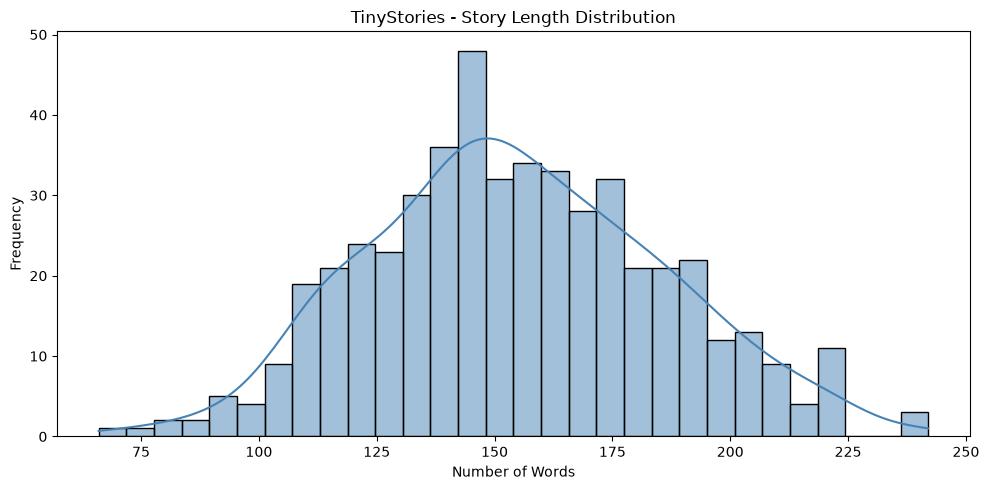

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("TinyStories - Story Length Distribution")

plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    results_dir / "story_length_distribution.png",
    dpi=300
)

plt.show()

In [13]:
# Join stories using newline separators

train_text = "\n\n".join(train_stories)

validation_text = "\n\n".join(validation_stories)

print("Training characters:", len(train_text))

print("Validation characters:", len(validation_text))

print("\nSample text:")

print(train_text[:500])

Training characters: 403432
Validation characters: 69909

Sample text:
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them b


In [14]:
# Build the vocabulary using only training data

characters = sorted(set(train_text))

# Add an unknown token for unseen characters
vocabulary = ["<UNK>"] + characters

vocab_size = len(vocabulary)

# Character to integer
stoi = {
    character: index
    for index, character in enumerate(vocabulary)
}

# Integer to character
itos = {
    index: character
    for index, character in enumerate(vocabulary)
}

print("Vocabulary size:", vocab_size)

print("\nVocabulary:")

print(vocabulary)

print("\nSample token mappings:")

print(list(stoi.items())[:20])

Vocabulary size: 75

Vocabulary:
['<UNK>', '\n', ' ', '!', '"', '$', "'", ',', '-', '.', '0', '1', '2', '3', '8', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', 'â', 'œ', '“', '”', '€', '™']

Sample token mappings:
[('<UNK>', 0), ('\n', 1), (' ', 2), ('!', 3), ('"', 4), ('$', 5), ("'", 6), (',', 7), ('-', 8), ('.', 9), ('0', 10), ('1', 11), ('2', 12), ('3', 13), ('8', 14), (':', 15), (';', 16), ('?', 17), ('A', 18), ('B', 19)]


In [15]:
def encode(text):

    return [
        stoi.get(character, stoi["<UNK>"])
        for character in text
    ]


def decode(tokens):

    return "".join(
        itos[int(token)]
        if int(token) != stoi["<UNK>"]
        else "�"
        for token in tokens
    )


sample_text = "Once upon a time"

encoded_text = encode(sample_text)

decoded_text = decode(encoded_text)

print("Original text:", sample_text)

print("Encoded text:", encoded_text)

print("Decoded text:", decoded_text)

Original text: Once upon a time
Encoded text: [32, 56, 45, 47, 2, 63, 58, 57, 56, 2, 43, 2, 62, 51, 55, 47]
Decoded text: Once upon a time


In [16]:
train_data = torch.tensor(
    encode(train_text),
    dtype=torch.long
)

validation_data = torch.tensor(
    encode(validation_text),
    dtype=torch.long
)

print("Training tensor shape:", train_data.shape)

print("Validation tensor shape:", validation_data.shape)

print("\nFirst 30 training tokens:")

print(train_data[:30])

print("\nDecoded tokens:")

print(decode(train_data[:30].tolist()))

Training tensor shape: torch.Size([403432])
Validation tensor shape: torch.Size([69909])

First 30 training tokens:
tensor([32, 56, 47,  2, 46, 43, 67,  7,  2, 43,  2, 54, 51, 62, 62, 54, 47,  2,
        49, 51, 60, 54,  2, 56, 43, 55, 47, 46,  2, 29])

Decoded tokens:
One day, a little girl named L


In [17]:
# Model configuration

BLOCK_SIZE = 64

BATCH_SIZE = 16

N_EMBD = 64

N_HEAD = 4

N_LAYER = 2

DROPOUT = 0.1

LEARNING_RATE = 3e-4

EPOCHS = 3

STEPS_PER_EPOCH = 100

EVAL_STEPS = 20

print("Hyperparameters configured successfully!")

Hyperparameters configured successfully!


In [18]:
def get_batch(split, generator=None):

    if split == "train":
        data = train_data
    elif split == "validation":
        data = validation_data
    else:
        raise ValueError("Invalid dataset split")

    # Select random starting positions
    indices = torch.randint(
        0,
        len(data) - BLOCK_SIZE,
        (BATCH_SIZE,),
        generator=generator
    )

    # Input sequences
    x = torch.stack([
        data[int(i):int(i) + BLOCK_SIZE]
        for i in indices
    ])

    # Target sequences shifted by one token
    y = torch.stack([
        data[int(i) + 1:int(i) + BLOCK_SIZE + 1]
        for i in indices
    ])

    return x.to(device), y.to(device)


xb, yb = get_batch("train")

print("Input batch shape:", xb.shape)

print("Target batch shape:", yb.shape)

print("\nInput sequence:")

print(decode(xb[0].tolist()))

print("\nTarget sequence:")

print(decode(yb[0].tolist()))

Input batch shape: torch.Size([16, 64])
Target batch shape: torch.Size([16, 64])

Input sequence:
 in the park. One day, Max was running very fast when he fell an

Target sequence:
in the park. One day, Max was running very fast when he fell and


In [19]:
class MultiHeadSelfAttention(nn.Module):

    def __init__(
        self,
        n_embd,
        n_head,
        block_size,
        dropout
    ):

        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=n_embd,
            num_heads=n_head,
            dropout=dropout,
            batch_first=True
        )

        # Create causal attention mask
        mask = torch.triu(
            torch.ones(
                block_size,
                block_size,
                dtype=torch.bool
            ),
            diagonal=1
        )

        self.register_buffer(
            "mask",
            mask,
            persistent=False
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        sequence_length = x.size(1)

        output, _ = self.attention(
            x,
            x,
            x,
            attn_mask=self.mask[
                :sequence_length,
                :sequence_length
            ],
            need_weights=False
        )

        return self.dropout(output)


print("Masked multi-head attention created!")

Masked multi-head attention created!


In [20]:
class FeedForward(nn.Module):

    def __init__(self, n_embd, dropout):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                n_embd,
                4 * n_embd
            ),

            nn.GELU(),

            nn.Linear(
                4 * n_embd,
                n_embd
            ),

            nn.Dropout(dropout)

        )

    def forward(self, x):

        return self.network(x)


print("Feed-forward network created!")

Feed-forward network created!


In [21]:
class TransformerBlock(nn.Module):

    def __init__(
        self,
        n_embd,
        n_head,
        block_size,
        dropout
    ):

        super().__init__()

        self.attention = MultiHeadSelfAttention(
            n_embd,
            n_head,
            block_size,
            dropout
        )

        self.feed_forward = FeedForward(
            n_embd,
            dropout
        )

        self.ln1 = nn.LayerNorm(n_embd)

        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):

        # Attention with residual connection
        x = x + self.attention(
            self.ln1(x)
        )

        # Feed-forward with residual connection
        x = x + self.feed_forward(
            self.ln2(x)
        )

        return x


print("Transformer block created!")

Transformer block created!


In [22]:
class TinyTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        block_size,
        n_embd,
        n_head,
        n_layer,
        dropout
    ):

        super().__init__()

        self.block_size = block_size

        # Token embeddings
        self.token_embedding = nn.Embedding(
            vocab_size,
            n_embd
        )

        # Positional embeddings
        self.position_embedding = nn.Embedding(
            block_size,
            n_embd
        )

        self.embedding_dropout = nn.Dropout(dropout)

        # Transformer blocks
        self.blocks = nn.Sequential(*[

            TransformerBlock(
                n_embd,
                n_head,
                block_size,
                dropout
            )

            for _ in range(n_layer)

        ])

        # Final layer normalization
        self.final_norm = nn.LayerNorm(n_embd)

        # Language model output head
        self.lm_head = nn.Linear(
            n_embd,
            vocab_size
        )

        # Initialize model weights
        self.apply(self.initialize_weights)

    def initialize_weights(self, module):

        if isinstance(module, nn.Linear):

            nn.init.normal_(
                module.weight,
                mean=0.0,
                std=0.02
            )

            if module.bias is not None:
                nn.init.zeros_(module.bias)

        elif isinstance(module, nn.Embedding):

            nn.init.normal_(
                module.weight,
                mean=0.0,
                std=0.02
            )

    def forward(self, idx, targets=None):

        B, T = idx.shape

        if T > self.block_size:
            raise ValueError("Context length exceeded")

        # Token embedding
        token_embeddings = self.token_embedding(idx)

        # Positional embedding
        positions = torch.arange(
            T,
            device=idx.device
        )

        position_embeddings = self.position_embedding(
            positions
        )

        # Combine embeddings
        x = token_embeddings + position_embeddings

        x = self.embedding_dropout(x)

        # Apply Transformer blocks
        x = self.blocks(x)

        x = self.final_norm(x)

        # Predict next tokens
        logits = self.lm_head(x)

        loss = None

        if targets is not None:

            B, T, C = logits.shape

            loss = F.cross_entropy(
                logits.reshape(B * T, C),
                targets.reshape(B * T)
            )

        return logits, loss


print("Tiny Transformer model created successfully!")

Tiny Transformer model created successfully!


In [23]:
# Store the model configuration

model_config = {

    "vocab_size": vocab_size,

    "block_size": BLOCK_SIZE,

    "n_embd": N_EMBD,

    "n_head": N_HEAD,

    "n_layer": N_LAYER,

    "dropout": DROPOUT

}

torch.manual_seed(SEED)

model = TinyTransformer(
    **model_config
).to(device)

print(model)

TinyTransformer(
  (token_embedding): Embedding(75, 64)
  (position_embedding): Embedding(64, 64)
  (embedding_dropout): Dropout(p=0.1, inplace=False)
  (blocks): Sequential(
    (0): TransformerBlock(
      (attention): MultiHeadSelfAttention(
        (attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (feed_forward): FeedForward(
        (network): Sequential(
          (0): Linear(in_features=64, out_features=256, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=256, out_features=64, bias=True)
          (3): Dropout(p=0.1, inplace=False)
        )
      )
      (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (ln2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (1): TransformerBlock(
      (attention): MultiHeadSelfAttention(
        (attenti

In [24]:
total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_parameters:,}")

print(f"Trainable parameters: {trainable_parameters:,}")

print("Model device:", next(model.parameters()).device)

Total parameters: 113,867
Trainable parameters: 113,867
Model device: cpu


In [25]:
optimizer = torch.optim.AdamW(

    model.parameters(),

    lr=LEARNING_RATE

)

# Test forward propagation

xb, yb = get_batch("train")

model.eval()

with torch.no_grad():

    logits, loss = model(xb, yb)

print("Input shape:", xb.shape)

print("Output logits shape:", logits.shape)

print("Initial loss:", loss.item())

print("Optimizer: AdamW")

print("Loss function: Cross-Entropy")

Input shape: torch.Size([16, 64])
Output logits shape: torch.Size([16, 64, 75])
Initial loss: 4.354767799377441
Optimizer: AdamW
Loss function: Cross-Entropy


In [26]:
@torch.no_grad()

def estimate_loss(current_model):

    previous_mode = current_model.training

    current_model.eval()

    results = {}

    for split in ["train", "validation"]:

        losses = []

        # Fixed evaluation batches for fair comparisons
        eval_generator = torch.Generator()

        eval_generator.manual_seed(
            SEED + (100 if split == "train" else 200)
        )

        for _ in range(EVAL_STEPS):

            X, Y = get_batch(
                split,
                generator=eval_generator
            )

            _, loss = current_model(X, Y)

            losses.append(loss.item())

        results[split] = float(
            np.mean(losses)
        )

    current_model.train(previous_mode)

    return results


initial_losses = estimate_loss(model)

print("Initial training loss:", initial_losses["train"])

print("Initial validation loss:",
      initial_losses["validation"])

Initial training loss: 4.349144673347473
Initial validation loss: 4.349950313568115


In [27]:
def train_model(
    current_model,
    current_optimizer,
    epochs
):

    history = []

    train_generator = torch.Generator()

    train_generator.manual_seed(SEED)

    for epoch in range(epochs):

        start_time = time.perf_counter()

        current_model.train()

        running_loss = 0.0

        for step in range(STEPS_PER_EPOCH):

            # Get training batch
            X, Y = get_batch(
                "train",
                generator=train_generator
            )

            # Clear previous gradients
            current_optimizer.zero_grad(
                set_to_none=True
            )

            # Forward propagation
            logits, loss = current_model(X, Y)

            # Backpropagation
            loss.backward()

            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(
                current_model.parameters(),
                max_norm=1.0
            )

            # Update weights
            current_optimizer.step()

            running_loss += loss.item()

        average_batch_loss = (
            running_loss / STEPS_PER_EPOCH
        )

        # Evaluate training and validation datasets
        losses = estimate_loss(current_model)

        validation_perplexity = math.exp(
            losses["validation"]
        )

        elapsed_time = (
            time.perf_counter() - start_time
        )

        history.append({

            "epoch": epoch + 1,

            "batch_loss": average_batch_loss,

            "train_loss": losses["train"],

            "validation_loss": losses["validation"],

            "perplexity": validation_perplexity,

            "time_seconds": elapsed_time

        })

        print(

            f"Epoch {epoch + 1}/{epochs} | "

            f"Train Loss: {losses['train']:.4f} | "

            f"Validation Loss: {losses['validation']:.4f} | "

            f"Perplexity: {validation_perplexity:.4f} | "

            f"Time: {elapsed_time:.2f}s"

        )

    return pd.DataFrame(history)

In [28]:
print("Starting model training...\n")

torch.manual_seed(SEED)

history_df = train_model(

    current_model=model,

    current_optimizer=optimizer,

    epochs=EPOCHS

)

print("\nTraining completed!")

display(history_df.round(4))

Starting model training...

Epoch 1/3 | Train Loss: 2.8999 | Validation Loss: 2.9144 | Perplexity: 18.4374 | Time: 5.98s
Epoch 2/3 | Train Loss: 2.5416 | Validation Loss: 2.5525 | Perplexity: 12.8394 | Time: 6.86s
Epoch 3/3 | Train Loss: 2.4209 | Validation Loss: 2.4298 | Perplexity: 11.3569 | Time: 6.85s

Training completed!


,epoch,batch_loss,train_loss,validation_loss,perplexity,time_seconds
0,1,3.4232,2.8999,2.9144,18.4374,5.9810
1,2,2.7113,2.5416,2.5525,12.8394,6.8604
2,3,2.5064,2.4209,2.4298,11.3569,6.8465


In [29]:
history_df.to_csv(

    results_dir / "training_history.csv",

    index=False

)

display(history_df)

print("Training history saved successfully!")

,epoch,batch_loss,train_loss,validation_loss,perplexity,time_seconds
0,1,3.423159,2.899923,2.914382,18.437410,5.980981
1,2,2.711311,2.541562,2.552517,12.839375,6.860403
2,3,2.506441,2.420909,2.429821,11.356850,6.846492


Training history saved successfully!


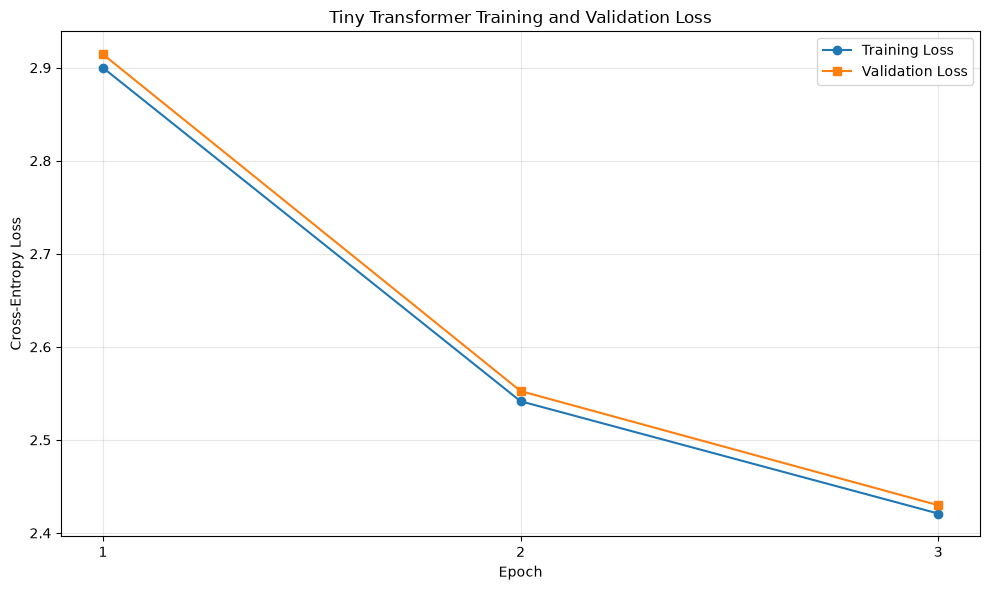

In [30]:
plt.figure(figsize=(10, 6))

plt.plot(

    history_df["epoch"],

    history_df["train_loss"],

    marker="o",

    label="Training Loss"

)

plt.plot(

    history_df["epoch"],

    history_df["validation_loss"],

    marker="s",

    label="Validation Loss"

)

plt.title("Tiny Transformer Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Cross-Entropy Loss")

plt.xticks(history_df["epoch"])

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    results_dir / "loss_curves.png",

    dpi=300

)

plt.show()

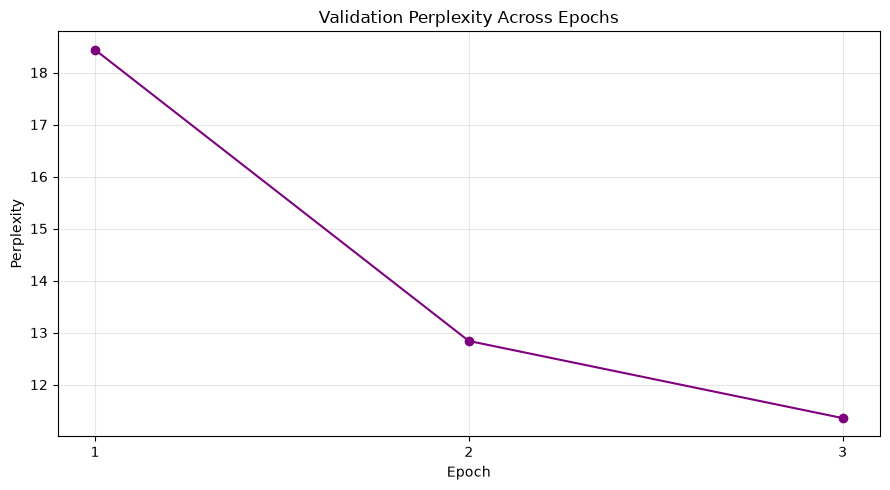

In [31]:
plt.figure(figsize=(9, 5))

plt.plot(

    history_df["epoch"],

    history_df["perplexity"],

    marker="o",

    color="purple"

)

plt.title("Validation Perplexity Across Epochs")

plt.xlabel("Epoch")

plt.ylabel("Perplexity")

plt.xticks(history_df["epoch"])

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    results_dir / "perplexity_curve.png",

    dpi=300

)

plt.show()

In [32]:
final_losses = estimate_loss(model)

final_train_loss = final_losses["train"]

final_validation_loss = final_losses["validation"]

final_perplexity = math.exp(
    final_validation_loss
)

print("=" * 50)

print("FINAL MODEL EVALUATION")

print("=" * 50)

print(f"Training Loss: {final_train_loss:.4f}")

print(f"Validation Loss: {final_validation_loss:.4f}")

print(f"Validation Perplexity: {final_perplexity:.4f}")

print(f"Total Parameters: {total_parameters:,}")

FINAL MODEL EVALUATION
Training Loss: 2.4209
Validation Loss: 2.4298
Validation Perplexity: 11.3569
Total Parameters: 113,867


In [33]:
evaluation_df = pd.DataFrame([{

    "Model": "Tiny Transformer",

    "Layers": N_LAYER,

    "Attention Heads": N_HEAD,

    "Embedding Dimension": N_EMBD,

    "Epochs": EPOCHS,

    "Training Loss": final_train_loss,

    "Validation Loss": final_validation_loss,

    "Perplexity": final_perplexity,

    "Parameters": total_parameters

}])

evaluation_df.to_csv(

    results_dir / "evaluation.csv",

    index=False

)

display(evaluation_df.round(4))

,Model,Layers,Attention Heads,Embedding Dimension,Epochs,Training Loss,Validation Loss,Perplexity,Parameters
0,Tiny Transformer,2,4,64,3,2.4209,2.4298,11.3569,113867


In [34]:
@torch.no_grad()

def generate_text(

    current_model,

    prompt,

    max_new_tokens=200,

    temperature=0.8,

    top_k=20,

    seed=42

):

    if not prompt:
        raise ValueError("Prompt cannot be empty")

    if temperature <= 0:
        raise ValueError("Temperature must be positive")

    current_model.eval()

    torch.manual_seed(seed)

    # Encode the prompt
    idx = torch.tensor(

        [encode(prompt)],

        dtype=torch.long,

        device=device

    )

    for _ in range(max_new_tokens):

        # Use the latest context tokens
        idx_cond = idx[
            :, -current_model.block_size:
        ]

        # Predict next-token logits
        logits, _ = current_model(idx_cond)

        # Select the last token prediction
        logits = logits[:, -1, :]

        # Apply temperature
        logits = logits / temperature

        # Apply top-k sampling
        if top_k is not None:

            k = min(top_k, logits.size(-1))

            if k < 1:
                raise ValueError("top_k must be positive")

            values, _ = torch.topk(logits, k)

            logits = logits.masked_fill(

                logits < values[:, [-1]],

                float("-inf")

            )

        # Convert logits into probabilities
        probabilities = F.softmax(
            logits,
            dim=-1
        )

        # Sample the next token
        next_token = torch.multinomial(

            probabilities,

            num_samples=1

        )

        # Append the predicted token
        idx = torch.cat(

            (idx, next_token),

            dim=1

        )

    # Decode generated tokens
    generated_text = decode(
        idx[0].tolist()
    )

    return generated_text


print("Text generation function created!")

Text generation function created!


In [35]:
prompt = "Once upon a time"

generated_story = generate_text(

    current_model=model,

    prompt=prompt,

    max_new_tokens=200,

    temperature=0.8,

    top_k=20

)

print("Prompt:", prompt)

print("\nGenerated Story:\n")

print(generated_story)

Prompt: Once upon a time

Generated Story:

Once upon a timerls isy, hend wale thehou as he bug orolld and t wan bed tindd tor ave lus d aliwe sthher are aty mo a swouth f me the and mallr wa wtovy thee toilaawed s l th s illerlomy t be, totom and al the tery 


In [36]:
prompts = [

    "Once upon a time",

    "One day, a little boy",

    "There was a little girl",

    "The little dog",

    "In a beautiful forest"

]

generated_results = []

for prompt in prompts:

    story = generate_text(

        current_model=model,

        prompt=prompt,

        max_new_tokens=200,

        temperature=0.8,

        top_k=20

    )

    generated_results.append({

        "Prompt": prompt,

        "Generated Story": story

    })

    print("=" * 60)

    print("Prompt:", prompt)

    print("\nGenerated Story:")

    print(story)

    print()


stories_df = pd.DataFrame(generated_results)

stories_df.to_csv(

    results_dir / "generated_stories.csv",

    index=False

)

display(stories_df)

Prompt: Once upon a time

Generated Story:
Once upon a timerls isy, hend wale thehou as he bug orolld and t wan bed tindd tor ave lus d aliwe sthher are aty mo a swouth f me the and mallr wa wtovy thee toilaawed s l th s illerlomy t be, totom and al the tery 

Prompt: One day, a little boy

Generated Story:
One day, a little boy ls isanle nd wale thehou as he bug ledeld and t wan bed tindd tor ave lus d aliwe sthher are aty mo a swouth f me the and mallr wa wtovy thee toilaawed s l th s illerlomy t be, totom and al the tery 

Prompt: There was a little girl

Generated Story:
There was a little girlrls isy, hend wale thehouf s he bug ledeld and t wan bed tindd tor ave lus d aliwe sthher are aty mo a swouth f me the and mallr wa wtovy thee toilaawed s l th s illerlomy t be, totom and al the tery 

Prompt: The little dog

Generated Story:
The little dog ls isanle nd wale thehouf s he but leslld and t wan bed tindd tor ave lus d aliwe sthher are aty mo a swouth f me the and mallr wa wtovy 

,Prompt,Generated Story
0,Once upon a time,"Once upon a timerls isy, hend wale thehou as h..."
1,"One day, a little boy","One day, a little boy ls isanle nd wale thehou..."
2,There was a little girl,"There was a little girlrls isy, hend wale theh..."
3,The little dog,The little dog ls isanle nd wale thehouf s he ...
4,In a beautiful forest,In a beautiful forest ls isyele nd wale thehou...


In [37]:
temperatures = [

    0.3,

    0.7,

    1.0,

    1.5

]

temperature_results = []

for temperature in temperatures:

    story = generate_text(

        current_model=model,

        prompt="Once upon a time",

        max_new_tokens=200,

        temperature=temperature,

        top_k=20

    )

    temperature_results.append({

        "Temperature": temperature,

        "Generated Story": story

    })

    print("=" * 60)

    print("Temperature:", temperature)

    print(story)

    print()


temperature_df = pd.DataFrame(
    temperature_results
)

temperature_df.to_csv(

    results_dir / "temperature_experiments.csv",

    index=False

)

Temperature: 0.3
Once upon a time le the he the and the the s he the the the are the and and and the aro t the the the he to the the the wouthe the the and and and the s the the ithe the s and t the wand the the the the the the the a

Temperature: 0.7
Once upon a timerls is fle nd wale the the s he but orould and thed and atind s the pe lus d an we sthher are athe o a swouth f me the and mallr wa wavey thee toilaawed s l th s illerlomy t be, totom and al the tery 

Temperature: 1.0
Once upon a timerls isy,, snd wale llghouf.s he bug orolld apla g co bed tin datop ave lus d aliwe sthhd warund tye te swouch f meand peep mallr ww wte tithee taciaawed s l th s illeol my t be, totom nar al  he tery 

Temperature: 1.5
Once upon a timerls isy,,hen, walko. ghy b.s he bug leslld,aila T"€?I coutiy drtop aveolus d a fuy st,hdr aruivyyye we wwouchykd.eat Tpeep mallr ww wtcyyit wed dilaawedos liyt s illeol my h br, totom nar al  he canhk



In [38]:
def run_experiment(

    experiment_name,

    n_layer,

    n_head,

    epochs

):

    print("\n" + "=" * 60)

    print(experiment_name)

    print("=" * 60)

    # Reset random seed
    torch.manual_seed(SEED)

    experiment_config = {

        "vocab_size": vocab_size,

        "block_size": BLOCK_SIZE,

        "n_embd": N_EMBD,

        "n_head": n_head,

        "n_layer": n_layer,

        "dropout": DROPOUT

    }

    # Initialize a new model
    experiment_model = TinyTransformer(

        **experiment_config

    ).to(device)

    experiment_optimizer = torch.optim.AdamW(

        experiment_model.parameters(),

        lr=LEARNING_RATE

    )

    # Train the model
    experiment_history = train_model(

        current_model=experiment_model,

        current_optimizer=experiment_optimizer,

        epochs=epochs

    )

    # Evaluate the trained model
    losses = estimate_loss(experiment_model)

    perplexity = math.exp(
        losses["validation"]
    )

    parameters = sum(

        p.numel()

        for p in experiment_model.parameters()

    )

    # Generate a story
    story = generate_text(

        current_model=experiment_model,

        prompt="Once upon a time",

        max_new_tokens=200,

        temperature=0.8,

        top_k=20

    )

    result = {

        "Experiment": experiment_name,

        "Layers": n_layer,

        "Heads": n_head,

        "Epochs": epochs,

        "Training Loss": losses["train"],

        "Validation Loss": losses["validation"],

        "Perplexity": perplexity,

        "Parameters": parameters,

        "Training Time": experiment_history[
            "time_seconds"
        ].sum(),

        "Generated Story": story

    }

    return result

In [39]:
baseline_result = {

    "Experiment": "Baseline",

    "Layers": N_LAYER,

    "Heads": N_HEAD,

    "Epochs": EPOCHS,

    "Training Loss": final_train_loss,

    "Validation Loss": final_validation_loss,

    "Perplexity": final_perplexity,

    "Parameters": total_parameters,

    "Training Time": history_df[
        "time_seconds"
    ].sum(),

    "Generated Story": generated_story

}

experiment_results = [
    baseline_result
]

print("Baseline experiment recorded!")

Baseline experiment recorded!


In [40]:
experiment_1 = run_experiment(

    experiment_name="Experiment 1 - Fewer Layers",

    n_layer=1,

    n_head=N_HEAD,

    epochs=EPOCHS

)

experiment_results.append(experiment_1)


Experiment 1 - Fewer Layers
Epoch 1/3 | Train Loss: 2.8700 | Validation Loss: 2.8813 | Perplexity: 17.8370 | Time: 3.26s
Epoch 2/3 | Train Loss: 2.5458 | Validation Loss: 2.5621 | Perplexity: 12.9630 | Time: 2.95s
Epoch 3/3 | Train Loss: 2.4400 | Validation Loss: 2.4529 | Perplexity: 11.6221 | Time: 3.74s


In [41]:
experiment_2 = run_experiment(

    experiment_name="Experiment 2 - Fewer Heads",

    n_layer=N_LAYER,

    n_head=2,

    epochs=EPOCHS

)

experiment_results.append(experiment_2)


Experiment 2 - Fewer Heads
Epoch 1/3 | Train Loss: 2.8987 | Validation Loss: 2.9125 | Perplexity: 18.4020 | Time: 6.55s
Epoch 2/3 | Train Loss: 2.5431 | Validation Loss: 2.5547 | Perplexity: 12.8676 | Time: 6.01s
Epoch 3/3 | Train Loss: 2.4181 | Validation Loss: 2.4247 | Perplexity: 11.2992 | Time: 5.89s


In [42]:
experiment_3 = run_experiment(

    experiment_name="Experiment 3 - Fewer Epochs",

    n_layer=N_LAYER,

    n_head=N_HEAD,

    epochs=2

)

experiment_results.append(experiment_3)


Experiment 3 - Fewer Epochs
Epoch 1/2 | Train Loss: 2.8992 | Validation Loss: 2.9134 | Perplexity: 18.4192 | Time: 6.52s
Epoch 2/2 | Train Loss: 2.5394 | Validation Loss: 2.5501 | Perplexity: 12.8078 | Time: 7.38s


In [43]:
experiments_df = pd.DataFrame(

    experiment_results

)

display(

    experiments_df.drop(

        columns=["Generated Story"]

    ).round(4)

)

experiments_df.to_csv(

    results_dir / "experiments.csv",

    index=False

)

print("\nLowest validation loss:")

best_index = experiments_df[
    "Validation Loss"
].idxmin()

display(

    experiments_df.loc[best_index]

)

,Experiment,Layers,Heads,Epochs,Training Loss,Validation Loss,Perplexity,Parameters,Training Time
0,Baseline,2,4,3,2.4209,2.4298,11.3569,113867,19.6879
1,Experiment 1 - Fewer Layers,1,4,3,2.4400,2.4529,11.6221,63883,9.9508
2,Experiment 2 - Fewer Heads,2,2,3,2.4181,2.4247,11.2992,113867,18.4511
3,Experiment 3 - Fewer Epochs,2,4,2,2.5394,2.5501,12.8078,113867,13.9003



Lowest validation loss:


Experiment                                Experiment 2 - Fewer Heads
Layers                                                             2
Heads                                                              2
Epochs                                                             3
Training Loss                                               2.418119
Validation Loss                                             2.424735
Perplexity                                                 11.299235
Parameters                                                    113867
Training Time                                              18.451108
Generated Story    Once upon a timerls tomele nd wale the ti as h...
Name: 2, dtype: object

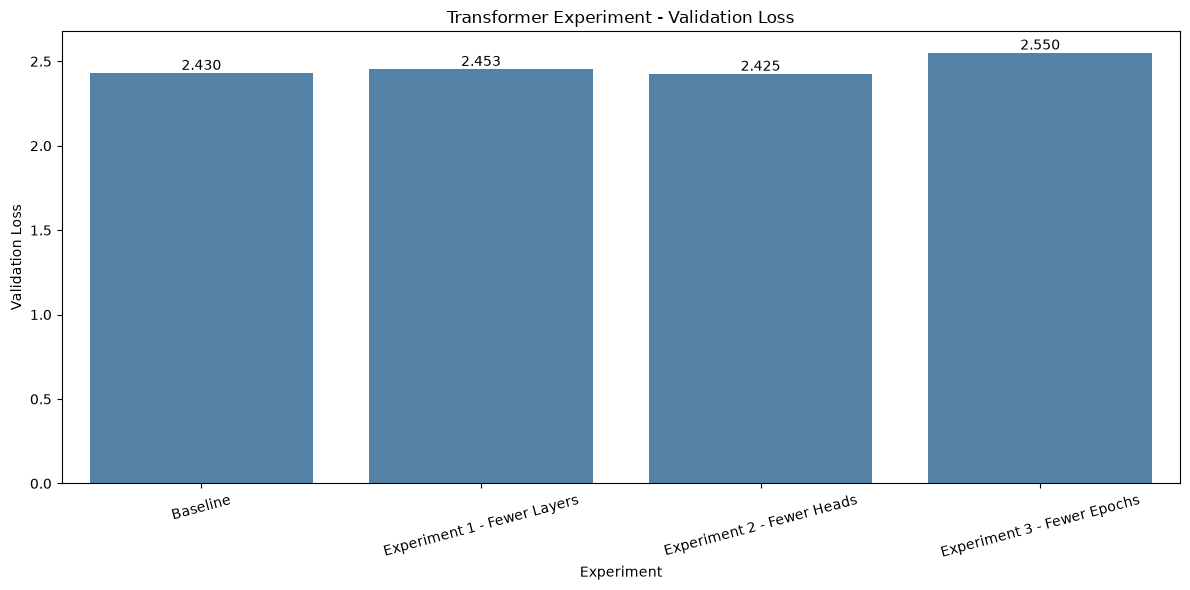

In [44]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(

    data=experiments_df,

    x="Experiment",

    y="Validation Loss",

    color="steelblue"

)

for container in ax.containers:

    ax.bar_label(

        container,

        fmt="%.3f"

    )

plt.title("Transformer Experiment - Validation Loss")

plt.xlabel("Experiment")

plt.ylabel("Validation Loss")

plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(

    results_dir / "experiment_comparison.png",

    dpi=300

)

plt.show()

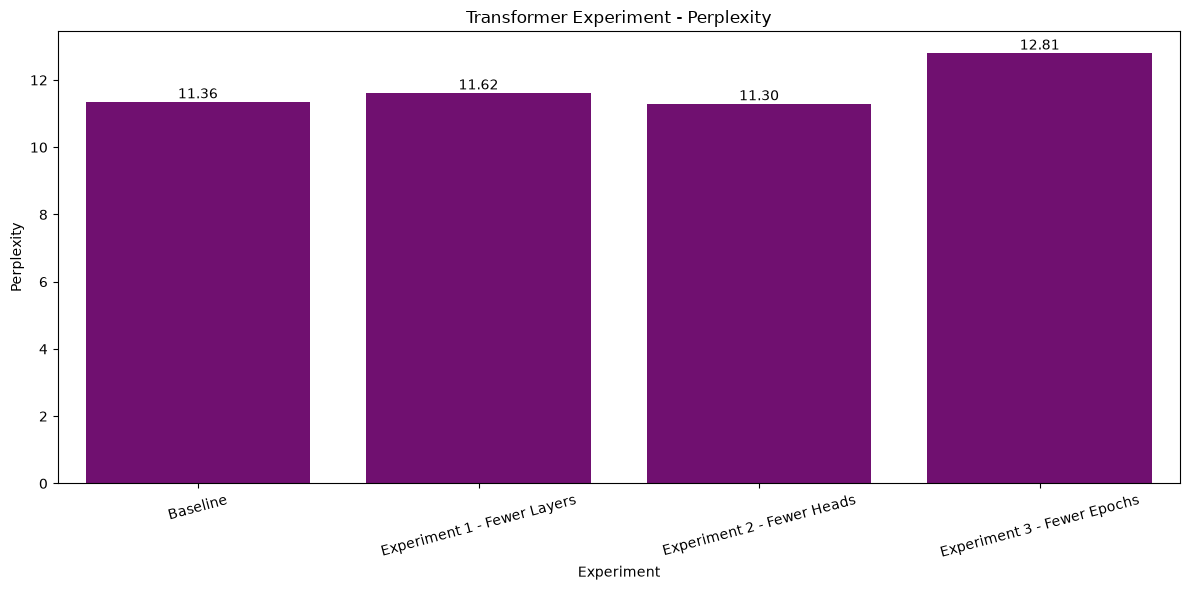

In [45]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(

    data=experiments_df,

    x="Experiment",

    y="Perplexity",

    color="purple"

)

for container in ax.containers:

    ax.bar_label(

        container,

        fmt="%.2f"

    )

plt.title("Transformer Experiment - Perplexity")

plt.xlabel("Experiment")

plt.ylabel("Perplexity")

plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(

    results_dir / "experiment_perplexity.png",

    dpi=300

)

plt.show()

In [46]:
for _, row in experiments_df.iterrows():

    print("=" * 60)

    print("Experiment:", row["Experiment"])

    print("Layers:", row["Layers"])

    print("Heads:", row["Heads"])

    print("Epochs:", row["Epochs"])

    print(
        f"Validation Loss: {row['Validation Loss']:.4f}"
    )

    print(
        f"Perplexity: {row['Perplexity']:.4f}"
    )

    print("\nGenerated Story:\n")

    print(row["Generated Story"])

    print()

Experiment: Baseline
Layers: 2
Heads: 4
Epochs: 3
Validation Loss: 2.4298
Perplexity: 11.3569

Generated Story:

Once upon a timerls isy, hend wale thehou as he bug orolld and t wan bed tindd tor ave lus d aliwe sthher are aty mo a swouth f me the and mallr wa wtovy thee toilaawed s l th s illerlomy t be, totom and al the tery 

Experiment: Experiment 1 - Fewer Layers
Layers: 1
Heads: 4
Epochs: 3
Validation Loss: 2.4529
Perplexity: 11.6221

Generated Story:

Once upon a timerls isye hend walam. thou toume bug ledeld and t wan bed tindd tor ave le md a toy sthher are aty mo a swouch f me the and mallr wa wavey thee toilaawed s lith s illerlomy t be, totom and al the tery 

Experiment: Experiment 2 - Fewer Heads
Layers: 2
Heads: 2
Epochs: 3
Validation Loss: 2.4247
Perplexity: 11.2992

Generated Story:

Once upon a timerls tomele nd wale the ti as he bug ledeld and thed and atin d tof ave lus d a toy sthher are aty mo a swoure f me the and mallr wo wavyy thee toilaawed s lith s ille lomy 

In [47]:
checkpoint = {

    "model_state_dict": model.state_dict(),

    "model_config": model_config,

    "vocabulary": vocabulary,

    "training_settings": {

        "batch_size": BATCH_SIZE,

        "learning_rate": LEARNING_RATE,

        "epochs": EPOCHS,

        "steps_per_epoch": STEPS_PER_EPOCH

    }

}

model_path = models_dir / "tiny_transformer.pt"

torch.save(

    checkpoint,

    model_path

)

print("Model saved successfully!")

print("Model location:", model_path)

print(

    "Model size:",

    round(
        model_path.stat().st_size / (1024 ** 2),
        2
    ),

    "MB"

)

Model saved successfully!
Model location: c:\Users\DELL\Downloads\LLM-Practical-Portfolio\Lab-03-Tiny-Transformer\models\tiny_transformer.pt
Model size: 0.45 MB


In [49]:
loaded_checkpoint = torch.load(

    model_path,

    map_location=device,

    weights_only=True

)

loaded_model = TinyTransformer(

    **loaded_checkpoint["model_config"]

).to(device)

loaded_model.load_state_dict(

    loaded_checkpoint["model_state_dict"]

)

loaded_model.eval()

# Restore tokenizer mappings

vocabulary = loaded_checkpoint["vocabulary"]

stoi = {

    character: index

    for index, character in enumerate(vocabulary)

}

itos = {

    index: character

    for index, character in enumerate(vocabulary)

}

print("Model loaded successfully!")

Model loaded successfully!


In [50]:
loaded_story = generate_text(

    current_model=loaded_model,

    prompt="Once upon a time",

    max_new_tokens=200,

    temperature=0.8,

    top_k=20,

    seed=42

)

original_story = generate_text(

    current_model=model,

    prompt="Once upon a time",

    max_new_tokens=200,

    temperature=0.8,

    top_k=20,

    seed=42

)

print("Generated story using the saved model:\n")

print(loaded_story)

print("\nCheckpoint verification:")

print("Matching outputs:", loaded_story == original_story)

Generated story using the saved model:

Once upon a timerls isy, hend wale thehou as he bug orolld and t wan bed tindd tor ave lus d aliwe sthher are aty mo a swouth f me the and mallr wa wtovy thee toilaawed s l th s illerlomy t be, totom and al the tery 

Checkpoint verification:
Matching outputs: True


In [51]:
import gradio as gr

print("Gradio imported successfully!")

Gradio imported successfully!


In [52]:
def story_chatbot(message, history):

    if not message.strip():

        return "Please enter a story opening."

    generated_story = generate_text(

        current_model=loaded_model,

        prompt=message,

        max_new_tokens=250,

        temperature=0.8,

        top_k=20

    )

    return generated_story

In [53]:
demo = gr.ChatInterface(

    fn=story_chatbot,

    title="Tiny Transformer AI Story Generator",

    description=(

        "A character-level Transformer language model "

        "trained from scratch using TinyStories."

    ),

    examples=[

        "Once upon a time",

        "One day, a little girl",

        "There was a little dog",

        "In a beautiful forest"

    ]

)

demo.launch(

    share=False,

    inline=False

)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [54]:
demo.close()

Closing server running on port: 7860


## Discussion

The Tiny Transformer implements several mechanisms to
improve language modelling performance.

Multi-head self-attention enables the model to learn
contextual relationships between tokens. Causal masking
prevents the model from accessing future tokens during
next-token prediction.

Residual connections and layer normalization improve
training stability and gradient flow. Dropout helps
reduce overfitting, while gradient clipping controls
excessively large gradients.

The AdamW optimizer is used to update model parameters
during training.

Different numbers of Transformer layers, attention heads
and training epochs were investigated to understand their
effects on validation loss, perplexity and text generation.

Temperature and top-k sampling were used to control
the diversity of generated text.

## Limitations

- Small training dataset.
- Limited training steps.
- Character-level tokenization.
- Limited context length.
- Possible repetition and grammatical errors.
- Limited long-range contextual understanding.

## Future Improvements

- Increase the training dataset size.
- Increase the number of training epochs.
- Experiment with larger embedding dimensions.
- Implement subword tokenization.
- Experiment with learning rate scheduling.
- Use GPU acceleration for larger models.
- Investigate longer context windows.